# Дипломный проект: рекомендательная система для интернет-магазина

## Неделя 2. Описание данных, валидация и генерация факторов

**Бизнес-задача.** Клиент - компания-ритейлер. Нужно повысить прибыль от допродаж за счёт блока рекомендаций на главной странице сайта. В блоке три места для товаров.

**Техническая постановка.** Для каждого пользователя нужно выбрать три товара, которые он с наибольшей вероятностью купит. Оборот напрямую оптимизировать нельзя (в данных нет цен и выручки), поэтому качество измеряем метрикой **Precision@3**: какая доля из трёх показанных товаров была куплена пользователем.

**Содержание ноутбука**

1. Загрузка и описание структуры данных
2. Статистический анализ событий
3. Дерево категорий и свойства товаров
4. Дополнительная задача от продакт-менеджера (топ-3 товара)
5. Построение валидации: разбиение по времени
6. Метрика Precision@3 и базовые решения
7. Генерация факторов: товар, пользователь, пара «пользователь–товар»
8. Проверка факторов и выводы

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

DATA_DIR = Path('.')

## 1. Загрузка и описание структуры данных

### 1.1. Лог событий `events.csv`

| Колонка | Описание |
|---|---|
| `timestamp` | время события |
| `visitorid` | идентификатор пользователя |
| `event` | тип события: `view` просмотр карточки товара, `addtocart` добавление в корзину, `transaction` покупка |
| `itemid` | идентификатор товара |
| `transactionid` | идентификатор транзакции |

In [2]:
events = pd.read_csv(DATA_DIR / 'events.csv')
print('Размер таблицы:', events.shape)
events.head()

Размер таблицы: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [3]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 116.1 MB


In [4]:
# Переводим время в datetime и проверяем пропуски и дубликаты
events['event_dt'] = pd.to_datetime(events['timestamp'], unit='ms')

print('Период данных:', events['event_dt'].min(), '—', events['event_dt'].max())
print('\nПропуски по колонкам:')
print(events.isna().sum())
print('\ntransactionid заполнен только у покупок:',
      events.loc[events['event'] != 'transaction', 'transactionid'].isna().all()
      and events.loc[events['event'] == 'transaction', 'transactionid'].notna().all())
print('Полных дубликатов строк:', events.duplicated().sum())

Период данных: 2015-05-03 03:00:04.384000 — 2015-09-18 02:59:47.788000

Пропуски по колонкам:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
event_dt               0
dtype: int64

transactionid заполнен только у покупок: True
Полных дубликатов строк: 460


Пропуски есть только в `transactionid`, и есть полные дубликаты строк.

In [5]:
events = events.drop_duplicates().sort_values('timestamp').reset_index(drop=True)
print('Записей после удаления дубликатов:', len(events))

summary = pd.Series({
    'Событий': len(events),
    'Уникальных пользователей': events['visitorid'].nunique(),
    'Уникальных товаров': events['itemid'].nunique(),
    'Покупок (событий transaction)': (events['event'] == 'transaction').sum(),
    'Уникальных транзакций (чеков)': events['transactionid'].nunique(),
    'Пользователей с покупками': events.loc[events['event'] == 'transaction', 'visitorid'].nunique(),
    'Товаров с покупками': events.loc[events['event'] == 'transaction', 'itemid'].nunique(),
})
summary.to_frame('Значение')

Записей после удаления дубликатов: 2755641


,Значение
Событий,2755641
Уникальных пользователей,1407580
Уникальных товаров,235061
Покупок (событий transaction),22457
Уникальных транзакций (чеков),17672
Пользователей с покупками,11719
Товаров с покупками,12025


## 2. Статистический анализ событий

### 2.1. Типы событий и воронка

In [6]:
EVENT_TYPES = ['view', 'addtocart', 'transaction']

event_stats = events['event'].value_counts().reindex(EVENT_TYPES).to_frame('Количество')
event_stats['Доля, %'] = (event_stats['Количество'] / len(events) * 100).round(2)
event_stats['Пользователей'] = events.groupby('event')['visitorid'].nunique().reindex(EVENT_TYPES)
event_stats['Товаров'] = events.groupby('event')['itemid'].nunique().reindex(EVENT_TYPES)
event_stats

,Количество,"Доля, %",Пользователей,Товаров
event,,,,
view,2664218,96.68,1404179,234838
addtocart,68966,2.50,37722,23903
transaction,22457,0.81,11719,12025


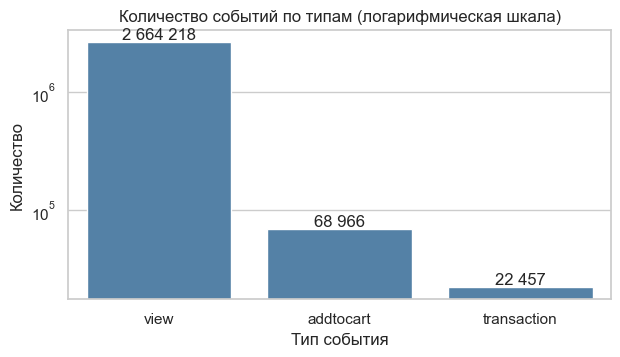

Корзина / просмотры: 2.59%
Покупки / корзина:   32.56%
Покупки / просмотры: 0.84%


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=event_stats.index, y=event_stats['Количество'], ax=ax, color='steelblue')
ax.set_yscale('log')
ax.set_title('Количество событий по типам (логарифмическая шкала)')
ax.set_xlabel('Тип события'); ax.set_ylabel('Количество')
for i, v in enumerate(event_stats['Количество']):
    ax.text(i, v, f'{v:,}'.replace(',', ' '), ha='center', va='bottom')
plt.show()

views, carts, trans = event_stats['Количество']
print(f'Корзина / просмотры: {carts / views:.2%}')
print(f'Покупки / корзина:   {trans / carts:.2%}')
print(f'Покупки / просмотры: {trans / views:.2%}')

Данные сильно несбалансированы: подавляющая часть событий это просмотры, покупки составляют меньше процента. Для рекомендаций это означает, что целевое событие (покупка) очень редкое, а просмотры и добавления в корзину нужно использовать как неявные сигналы интереса.

### 2.2. Динамика во времени

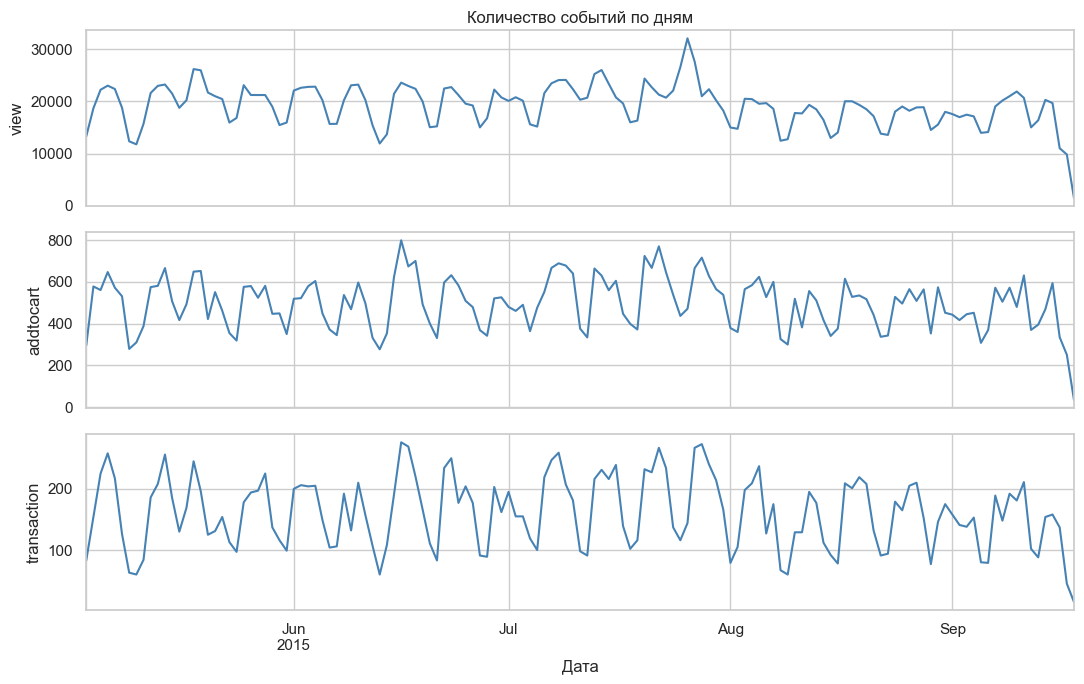

In [8]:
daily = (events.assign(date=events['event_dt'].dt.normalize())
               .groupby(['date', 'event']).size().unstack(fill_value=0)[EVENT_TYPES])

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, ev in zip(axes, EVENT_TYPES):
    daily[ev].plot(ax=ax, color='steelblue')
    ax.set_ylabel(ev)
axes[0].set_title('Количество событий по дням')
axes[-1].set_xlabel('Дата')
plt.tight_layout(); plt.show()

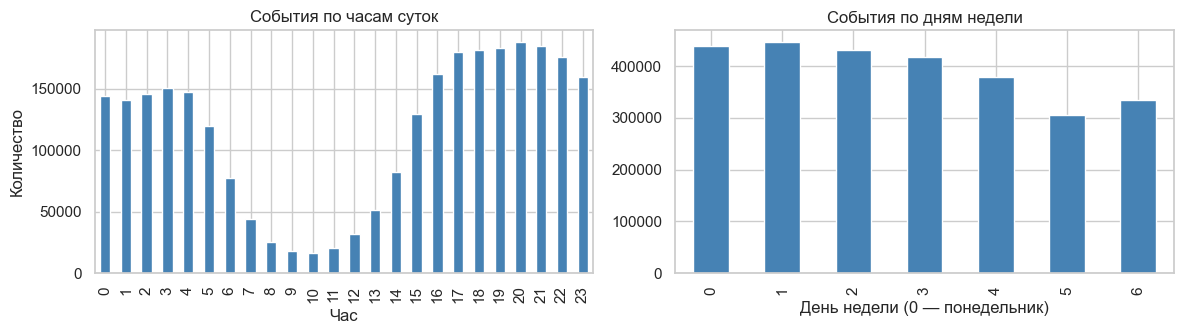

In [9]:
events['hour'] = events['event_dt'].dt.hour
events['day_of_week'] = events['event_dt'].dt.dayofweek   # 0 — понедельник

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
events.groupby('hour').size().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('События по часам суток'); axes[0].set_xlabel('Час'); axes[0].set_ylabel('Количество')
events.groupby('day_of_week').size().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('События по дням недели'); axes[1].set_xlabel('День недели (0 — понедельник)')
plt.tight_layout(); plt.show()

Данные покрывают около 4,5 месяцев, в среднем около 20 тысяч событий в день. Заметна недельная сезонность: в субботу и воскресенье активность примерно на четверть ниже, чем в начале недели. Есть и выраженный суточный цикл: минимум активности приходится на 8-11 часов UTC, максимум на 16-23 часа. 

### 2.3. Активность пользователей

Событий на пользователя:
count    1407580.00
mean           1.96
std           12.58
min            1.00
50%            1.00
75%            2.00
90%            3.00
99%           13.00
max         7757.00
dtype: float64

Доля пользователей с единственным событием: 71.2%
Пользователей с более чем 500 событиями: 75


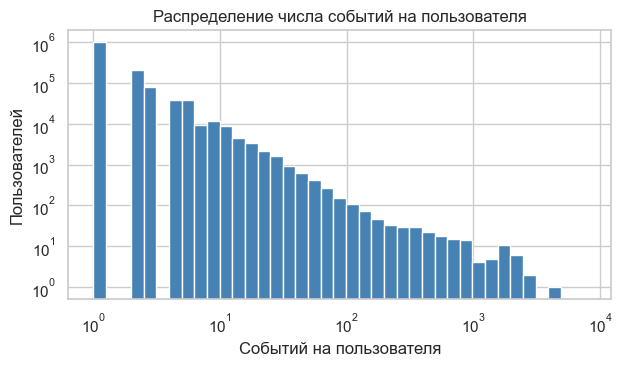

In [10]:
user_activity = events.groupby('visitorid').size()

print('Событий на пользователя:')
print(user_activity.describe(percentiles=[.5, .75, .9, .99]).round(2))
print(f'\nДоля пользователей с единственным событием: {(user_activity == 1).mean():.1%}')
print(f'Пользователей с более чем 500 событиями: {(user_activity > 500).sum()}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(user_activity, bins=np.logspace(0, np.log10(user_activity.max()), 40), color='steelblue')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Распределение числа событий на пользователя')
ax.set_xlabel('Событий на пользователя'); ax.set_ylabel('Пользователей')
plt.show()

Большинство пользователей совершили одно-два события, то есть истории по ним почти нет (проблема холодного старта). При этом есть небольшое число аномально активных посетителей с тысячами событий.

### 2.4. Популярность товаров

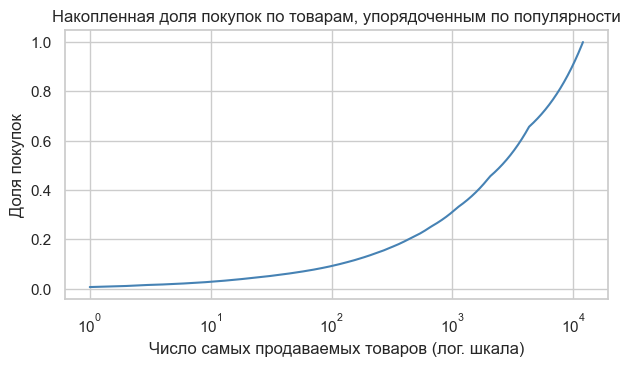

Топ-3 товаров дают 1.4% всех покупок
Топ-10 товаров дают 2.7% всех покупок
Топ-100 товаров дают 9.1% всех покупок
Топ-1000 товаров дают 31.1% всех покупок
Товаров, купленных всего один раз: 64.1% от купленных товаров


In [11]:
item_trans = events.loc[events['event'] == 'transaction', 'itemid'].value_counts()
cum_share = item_trans.cumsum() / item_trans.sum()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cum_share) + 1), cum_share.values, color='steelblue')
ax.set_xscale('log')
ax.set_title('Накопленная доля покупок по товарам, упорядоченным по популярности')
ax.set_xlabel('Число самых продаваемых товаров (лог. шкала)'); ax.set_ylabel('Доля покупок')
plt.show()

for n in (3, 10, 100, 1000):
    print(f'Топ-{n} товаров дают {cum_share.iloc[n - 1]:.1%} всех покупок')
print(f'Товаров, купленных всего один раз: {(item_trans == 1).mean():.1%} от купленных товаров')

In [12]:
# Как связаны покупки с предыдущими действиями того же пользователя
pairs = events.groupby(['visitorid', 'itemid', 'event']).size().unstack(fill_value=0)[EVENT_TYPES]
bought = pairs[pairs['transaction'] > 0]
print(f'Пар «пользователь–товар» всего: {len(pairs):,}'.replace(',', ' '))
print(f'Доля купленных пар, где пользователь просматривал товар: {(bought["view"] > 0).mean():.1%}')
print(f'Доля купленных пар, где товар добавляли в корзину:      {(bought["addtocart"] > 0).mean():.1%}')
print(f'Доля пар с корзиной, закончившихся покупкой:            {(pairs.loc[pairs["addtocart"] > 0, "transaction"] > 0).mean():.1%}')
print(f'Доля пар только с просмотрами, закончившихся покупкой:  {(pairs.loc[pairs["addtocart"] == 0, "transaction"] > 0).mean():.2%}')
del pairs, bought

Пар «пользователь–товар» всего: 2 145 179
Доля купленных пар, где пользователь просматривал товар: 89.6%
Доля купленных пар, где товар добавляли в корзину:      89.5%
Доля пар с корзиной, закончившихся покупкой:            30.7%
Доля пар только с просмотрами, закончившихся покупкой:  0.11%


Топ-100 товаров дают лишь около 9 % покупок, а почти две трети купленных товаров были куплены всего один раз. Поэтому рекомендация одних и тех же популярных товаров всем пользователям не может дать высокого качества.

Зато личная история пользователя это сильный сигнал: если товар добавлен в корзину, он покупается примерно в 31 % случаев, а без корзины, лишь в 0,1 % случаев. Около 10 % купленных пар не имеют события просмотра или корзины, лог неполный, часть событий в него не попала.

## 3. Дерево категорий и свойства товаров

### 3.1. Дерево категорий `category_tree.csv`

| Колонка | Описание |
|---|---|
| `categoryid` | идентификатор категории |
| `parentid` | идентификатор родительской категории (пусто у корневых категорий) |

In [13]:
cat_tree = pd.read_csv(DATA_DIR / 'category_tree.csv')
print('Размер таблицы:', cat_tree.shape)
print('Уникальных категорий:', cat_tree['categoryid'].nunique())
print('Корневых категорий (без родителя):', cat_tree['parentid'].isna().sum())
cat_tree.head()

Размер таблицы: (1669, 2)
Уникальных категорий: 1669
Корневых категорий (без родителя): 25


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


In [14]:
# Восстанавливаем дерево: для каждой категории находим корень и глубину
parent_of = cat_tree.dropna(subset=['parentid']).set_index('categoryid')['parentid'].astype(int).to_dict()

def path_to_root(cat):
    """Возвращает (корневую категорию, глубину) для категории cat."""
    depth, seen = 0, set()
    while cat in parent_of and cat not in seen:
        seen.add(cat)
        cat = parent_of[cat]
        depth += 1
    return cat, depth

cat_feats = cat_tree.copy()
cat_feats[['cat_root', 'cat_depth']] = [path_to_root(c) for c in cat_feats['categoryid']]
cat_feats = cat_feats.rename(columns={'parentid': 'cat_parent'})
cat_feats['cat_parent'] = cat_feats['cat_parent'].fillna(-1).astype(int)   # -1 — нет родителя

print('Распределение категорий по глубине в дереве:')
print(cat_feats['cat_depth'].value_counts().sort_index())
cat_feats.head()

Распределение категорий по глубине в дереве:
cat_depth
0     25
1    174
2    702
3    665
4     90
5     13
Name: count, dtype: int64


,categoryid,cat_parent,cat_root,cat_depth
0,1016,213,1532,3
1,809,169,395,3
2,570,9,653,3
3,1691,885,1579,2
4,536,1691,1579,3


### 3.2. Свойства товаров `item_properties_part1.csv`, `item_properties_part2.csv`

| Колонка | Описание |
|---|---|
| `timestamp` | момент записи значения свойства |
| `itemid` | идентификатор товара |
| `property` | название свойства; все названия, кроме `categoryid` и `available`, захешированы |
| `value` | значение свойства; текстовые значения захешированы, числа записаны с префиксом `n` |

In [15]:
PROP_FILES = [DATA_DIR / 'item_properties_part1.csv', DATA_DIR / 'item_properties_part2.csv']
KEEP_PROPS = ['categoryid', 'available', '790']
PROP_DTYPES = {'timestamp': 'int64', 'itemid': 'int32', 'property': 'str', 'value': 'str'}

pd.read_csv(PROP_FILES[0], nrows=8, dtype=PROP_DTYPES)

,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513
5,1436065200000,285026,available,0
6,1434250800000,89534,213,1121373
7,1431831600000,264312,6,319724


In [16]:
def read_properties(files, keep_props, chunksize=2_000_000):
    """Читает свойства товаров частями.

    Возвращает:
      kept           - все записи по свойствам из keep_props;
      prop_stats     - число товаров и число записей по каждому свойству;
      props_per_item - число разных свойств у каждого товара;
      n_rows         - общее число строк.
    """
    kept, pair_keys, counts, n_rows = [], [], {}, 0
    for f in files:
        for chunk in pd.read_csv(f, chunksize=chunksize, dtype=PROP_DTYPES):
            n_rows += len(chunk)
            for prop, cnt in chunk['property'].value_counts().items():
                counts[prop] = counts.get(prop, 0) + cnt
            # уникальные пары (товар, свойство) кодируем одним числом
            prop_code = chunk['property'].map({'categoryid': 2000, 'available': 2001})
            prop_code = prop_code.fillna(pd.to_numeric(chunk['property'], errors='coerce')).astype('int64')
            pair_keys.append(np.unique(chunk['itemid'].to_numpy('int64') * 10_000 + prop_code.to_numpy()))
            kept.append(chunk[chunk['property'].isin(keep_props)])
    pair_keys = np.unique(np.concatenate(pair_keys))
    codes, items_per_prop = np.unique(pair_keys % 10_000, return_counts=True)
    names = pd.Series(codes).map({2000: 'categoryid', 2001: 'available'}).fillna(pd.Series(codes).astype(str))
    prop_stats = pd.DataFrame({'property': names.values, 'items': items_per_prop})
    prop_stats['records'] = prop_stats['property'].map(counts)
    prop_stats = prop_stats.sort_values('items', ascending=False).reset_index(drop=True)
    props_per_item = pd.Series(np.unique(pair_keys // 10_000, return_counts=True)[1])
    return pd.concat(kept, ignore_index=True), prop_stats, props_per_item, n_rows

props, prop_stats, props_per_item, n_prop_rows = read_properties(PROP_FILES, KEEP_PROPS)
props['prop_dt'] = pd.to_datetime(props['timestamp'], unit='ms')

print(f'Всего записей о свойствах: {n_prop_rows:,}'.replace(',', ' '))
print('Уникальных свойств:', len(prop_stats))
print('Товаров со свойствами:', len(props_per_item))
print('Свойств на товар: медиана', int(props_per_item.median()), ', максимум', props_per_item.max())
print('Период записей:', props['prop_dt'].min(), '—', props['prop_dt'].max())

Всего записей о свойствах: 20 275 902
Уникальных свойств: 1104
Товаров со свойствами: 417053
Свойств на товар: медиана 27 , максимум 59
Период записей: 2015-05-10 03:00:00 — 2015-09-13 03:00:00


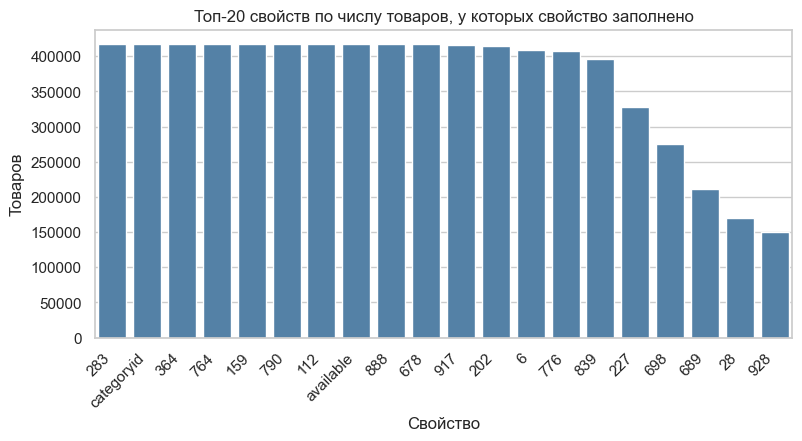

,property,items,records,"Доля товаров, %"
0,283,417053,597419,100.0
1,categoryid,417053,788214,100.0
2,364,417053,476486,100.0
3,764,417053,417053,100.0
4,159,417053,417053,100.0
5,790,417053,1790516,100.0
6,112,417053,417053,100.0
7,available,417053,1503639,100.0
8,888,417053,3000398,100.0
9,678,417019,481966,100.0


In [17]:
top20 = prop_stats.head(20).copy()
top20['Доля товаров, %'] = (top20['items'] / len(props_per_item) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=top20, x='property', y='items', ax=ax, color='steelblue', order=top20['property'])
ax.set_title('Топ-20 свойств по числу товаров, у которых свойство заполнено')
ax.set_xlabel('Свойство'); ax.set_ylabel('Товаров')
plt.xticks(rotation=45, ha='right'); plt.show()
top20

Свойств более тысячи, но заполнены у всех товаров только девять, среди них `categoryid` (категория) и `available` (наличие). Остальные захешированы, их смысл неизвестен. Свойства записаны еженедельными «снимками» с 10 мая по 13 сентября, то есть значение свойства может меняться со временем. Это важно для валидации: при расчёте факторов на момент времени *T* можно использовать только значения, записанные до *T*.

In [18]:
snapshots = (props.assign(date=props['prop_dt'].dt.date)
                  .groupby(['date', 'property']).size().unstack(fill_value=0))
print('Число записей по датам снимков:')
display(snapshots)

cat_changes = props[props['property'] == 'categoryid'].groupby('itemid')['value'].nunique()
print(f'Товаров, у которых менялась категория: {(cat_changes > 1).mean():.1%}')
avail = props[props['property'] == 'available']
print(f'Доля записей «товар в наличии» (available = 1): {(avail["value"] == "1").mean():.1%}')
print(f'Товаров из лога событий, для которых есть свойства: '
      f'{events["itemid"].drop_duplicates().isin(cat_changes.index).mean():.1%}')

Число записей по датам снимков:


property,790,available,categoryid
date,,,
2015-05-10,240223,232060,214522
2015-05-17,96940,81412,47398
2015-05-24,89586,73412,38478
2015-05-31,130457,116542,85934
2015-06-07,95766,79878,42764
2015-06-14,82173,66163,26111
2015-06-28,134577,120881,86691
2015-07-05,80638,64214,20091
2015-07-12,82050,65668,22549


Товаров, у которых менялась категория: 5.6%
Доля записей «товар в наличии» (available = 1): 42.6%
Товаров из лога событий, для которых есть свойства: 78.8%


Доля значений свойства 790 в формате одного числа: 100.0%
count    1.790516e+06
mean     1.289049e+05
std      2.148822e+06
min      0.000000e+00
25%      1.632000e+04
50%      4.632000e+04
75%      1.257600e+05
max      1.200000e+09
Name: value, dtype: float64


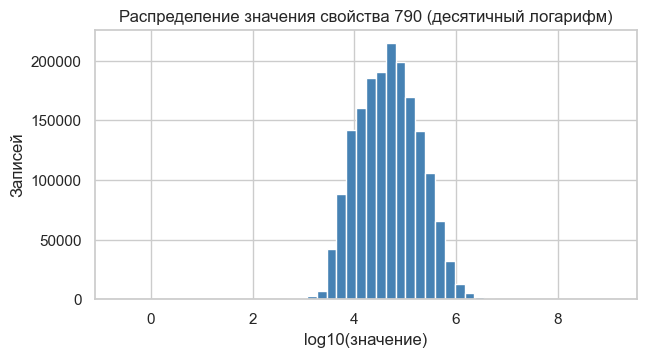

In [19]:
# Свойство 790 заполнено у всех товаров и содержит одно число.
# Гипотеза: это цена товара (в описании данных этого нет, поэтому дальше называем его prop_790).
p790 = props.loc[props['property'] == '790', 'value']
is_number = p790.str.fullmatch(r'n\d+(\.\d+)?')
print(f'Доля значений свойства 790 в формате одного числа: {is_number.mean():.1%}')
p790_num = p790[is_number].str[1:].astype(float)
print(p790_num.describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(p790_num[p790_num > 0]), bins=50, color='steelblue')
ax.set_title('Распределение значения свойства 790 (десятичный логарифм)')
ax.set_xlabel('log10(значение)'); ax.set_ylabel('Записей')
plt.show()

## 4. Дополнительная задача от продакт-менеджера

Вопрос Марии: если всем рекомендовать самые продаваемые товары, какую долю покупок это покроет? Берём статистику до 1 июля включительно, выбираем топ-3 товара по числу покупок и считаем их долю в покупках после 1 июля.

In [20]:
transactions = events[events['event'] == 'transaction']
PM_CUTOFF = pd.Timestamp('2015-07-02')            # до 1 июля включительно

before = transactions[transactions['event_dt'] < PM_CUTOFF]
after = transactions[transactions['event_dt'] >= PM_CUTOFF]

top3_pm = before['itemid'].value_counts().head(3)
share = after['itemid'].isin(top3_pm.index).mean()

print('Топ-3 товара по числу покупок до 1 июля включительно:')
print(top3_pm)
print(f'\nПокупок после 1 июля: {len(after)}')
print(f'Доля покупок после 1 июля, приходящаяся на топ-3 товара: {share:.2%}')

Топ-3 товара по числу покупок до 1 июля включительно:
itemid
119736    36
369447    31
7943      30
Name: count, dtype: int64

Покупок после 1 июля: 12608
Доля покупок после 1 июля, приходящаяся на топ-3 товара: 0.61%


**Ответ для Марии.** Три самых продаваемых товара покрывают менее одного процента будущих покупок. Рекомендовать всем одно и то же бессмысленно: нужны персональные рекомендации.

## 5. Построение валидации: разбиение по времени

Случайное разбиение здесь использовать нельзя. В реальной работе сервис обучается на прошлом и предсказывает будущее. Если перемешать события, модель увидит будущие действия пользователя (например, покупку после просмотра) и будущую популярность товаров. Качество на такой валидации окажется завышенным и не подтвердится после запуска. Стратификация по пользователям или товарам эту проблему не решает.

Поэтому используем **разбиение по времени**:

- **train** - события до 18 августа 2015 года (примерно 80 % лога);
- **test** - события с 18 августа по 18 сентября 2015 года (последний месяц).

In [21]:
SPLIT_DT = pd.Timestamp('2015-08-18')

train = events[events['event_dt'] < SPLIT_DT]
test = events[events['event_dt'] >= SPLIT_DT]
assert train['event_dt'].max() < test['event_dt'].min()

split_stats = pd.DataFrame({
    'train': [len(train), train['visitorid'].nunique(), train['itemid'].nunique(), (train['event'] == 'transaction').sum(),
              train['event_dt'].min().date(), train['event_dt'].max().date()],
    'test': [len(test), test['visitorid'].nunique(), test['itemid'].nunique(), (test['event'] == 'transaction').sum(),
             test['event_dt'].min().date(), test['event_dt'].max().date()],
}, index=['Событий', 'Пользователей', 'Товаров', 'Покупок', 'Начало периода', 'Конец периода'])
print(f'Доля событий в train: {len(train) / len(events):.1%}')
split_stats

Доля событий в train: 79.8%


,train,test
Событий,2199524,556117
Пользователей,1121163,311291
Товаров,212675,114853
Покупок,17834,4623
Начало периода,2015-05-03,2015-08-18
Конец периода,2015-08-17,2015-09-18


In [22]:
# Насколько тестовые покупатели и товары знакомы нам по обучающему периоду
test_trans = test[test['event'] == 'transaction']
test_buyers = test_trans['visitorid'].unique()
train_users, train_items = set(train['visitorid']), set(train['itemid'])

print(f'Покупателей в тесте: {len(test_buyers)}')
print(f'  из них есть в train: {np.mean([u in train_users for u in test_buyers]):.1%}')
print(f'Купленных в тесте товаров, встречавшихся в train: '
      f'{np.mean([i in train_items for i in test_trans["itemid"].unique()]):.1%}')

train_pairs = train[['visitorid', 'itemid']].drop_duplicates()
test_bought_pairs = test_trans[['visitorid', 'itemid']].drop_duplicates()
known = test_bought_pairs.merge(train_pairs, on=['visitorid', 'itemid'])
print(f'Купленных в тесте пар «пользователь–товар», уже встречавшихся в train: '
      f'{len(known) / len(test_bought_pairs):.1%}')

Покупателей в тесте: 2484
  из них есть в train: 14.1%
Купленных в тесте товаров, встречавшихся в train: 93.8%
Купленных в тесте пар «пользователь–товар», уже встречавшихся в train: 4.1%


Только около 14 % покупателей тестового периода встречались в обучающем периоде, остальные это новые посетители, о которых ничего не известно. Для них на главной странице можно показать только неперсональные рекомендации (популярные товары). Лишь около 4 % купленных в тесте пар «пользователь-товар» уже встречались в истории. Поэтому абсолютные значения Precision@3 в этой задаче будут низкими при любом подходе, и сравнивать модели нужно с базовыми решениями, а не с единицей.

## 6. Метрика Precision@3 и базовые решения

Для каждого пользователя, совершившего хотя бы одну покупку в тестовом периоде, формируем три рекомендации и считаем долю рекомендованных товаров, которые он купил. Итоговая метрика — среднее по таким пользователям.

In [ ]:
def precision_at_k(recs, actual, default, k=3):
    """Precision@k.

    recs    - словарь {пользователь: список рекомендованных товаров};
    actual  - словарь {пользователь: множество купленных товаров};
    default - рекомендации для пользователей, которых нет в recs.
    """
    scores = [len(set(recs.get(user, default)[:k]) & bought) / k for user, bought in actual.items()]
    return float(np.mean(scores))

actual_test = test_trans.groupby('visitorid')['itemid'].agg(set).to_dict()
train_trans = train[train['event'] == 'transaction']

# Базовое решение 1: три самых продаваемых товара за весь обучающий период
top_all = train_trans['itemid'].value_counts().head(3).index.tolist()

# Базовое решение 2: три самых продаваемых товара за последние 30 дней обучающего периода
recent_trans = train_trans[train_trans['event_dt'] >= SPLIT_DT - pd.Timedelta(days=30)]
top_recent = recent_trans['itemid'].value_counts().head(3).index.tolist()

# Базовое решение 3: товары из личной истории (сначала из корзины, затем последние просмотренные),
# недостающие места заполняем популярными товарами
hist = train[train['visitorid'].isin(actual_test.keys())]
hist = (hist.assign(in_cart=(hist['event'] == 'addtocart').astype(int))
            .groupby(['visitorid', 'itemid']).agg(in_cart=('in_cart', 'max'), last_dt=('event_dt', 'max'))
            .reset_index()
            .sort_values(['visitorid', 'in_cart', 'last_dt'], ascending=[True, False, False]))
personal = {user: (items.tolist()[:3] + top_recent)[:3]
            for user, items in hist.groupby('visitorid')['itemid']}

baselines = pd.DataFrame({
    'Precision@3': [precision_at_k({}, actual_test, top_all),
                    precision_at_k({}, actual_test, top_recent),
                    precision_at_k(personal, actual_test, top_recent)]
}, index=['Топ-3 за весь train', 'Топ-3 за последние 30 дней', 'Личная история + популярные'])
baselines['Precision@3'] = baselines['Precision@3'].round(5)
baselines

,Precision@3
Топ-3 за весь train,0.01047
Топ-3 за последние 30 дней,0.00993
Личная история + популярные,0.01919


Популярные товары дают Precision@3 около 0,010, а простое правило по личной истории почти вдвое больше, около 0,019, хотя история есть лишь у небольшой части покупателей. Эти значения точка отсчёта для моделей третьей недели: модель имеет смысл, только если она превосходит простые правила.

## 7. Генерация факторов

Факторы строятся функциями, которые получают историю событий и момент времени `cutoff` и используют только данные до этого момента. Одни и те же функции применяются и для обучения (граница внутри обучающего периода), и для итогового прогноза на тест (граница = `SPLIT_DT`). Так исключается утечка данных из будущего.

Группы факторов:

1. **Временные признаки события** - час, день недели, время суток.
2. **Факторы товара** - популярность (просмотры, корзины, покупки) за всё время и за последние 7 и 30 дней, конверсии, давность последнего события, категория и её место в дереве, наличие, свойство 790, популярность категории.
3. **Факторы пользователя** - активность по типам событий, число разных товаров, число активных дней, конверсии, давность последнего визита.
4. **Факторы пары «пользователь–товар»** - число просмотров, добавлений в корзину и покупок этого товара этим пользователем, давность взаимодействия, интерес пользователя к категории товара.

In [24]:
def get_day_period(hour):
    """Время суток по часу (как в генераторе факторов команды)."""
    if 3 <= hour < 7:
        return 'Dawn'
    elif 7 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 16:
        return 'Afternoon'
    elif 16 <= hour < 22:
        return 'Evening'
    return 'Night'

def add_time_features(df):
    """Добавляет к событиям временные признаки."""
    df = df.copy()
    df['hour'] = df['event_dt'].dt.hour
    df['day_of_week'] = df['event_dt'].dt.dayofweek
    df['is_weekend'] = (df['day_of_week'] >= 5).astype('int8')
    df['day_period'] = df['hour'].map(get_day_period)
    return df

events = add_time_features(events)
train = events[events['event_dt'] < SPLIT_DT]
test = events[events['event_dt'] >= SPLIT_DT]
events['day_period'].value_counts()

day_period
Evening      1078018
Night         765788
Dawn          494507
Afternoon     293450
Morning       123878
Name: count, dtype: int64

In [25]:
def count_events(df, keys, prefix):
    """Число просмотров, корзин и покупок в разрезе keys."""
    out = (df.groupby(keys + ['event']).size().unstack(fill_value=0)
             .reindex(columns=EVENT_TYPES, fill_value=0))
    out.columns = [f'{prefix}_views', f'{prefix}_carts', f'{prefix}_trans']
    return out.astype('int32')

def days_between(later, earlier):
    return ((later - earlier).dt.total_seconds() / 86400).astype('float32')

def property_asof(props, name, cutoff):
    """Последнее значение свойства name для каждого товара, записанное до cutoff."""
    p = props[(props['property'] == name) & (props['prop_dt'] < cutoff)].sort_values('timestamp')
    return p.groupby('itemid')['value'].last()

def build_item_features(ev, cutoff, props, cat_feats):
    """Факторы товара по истории ev (только события до cutoff)."""
    f = count_events(ev, ['itemid'], 'item')
    f['item_users'] = ev.groupby('itemid')['visitorid'].nunique().astype('int32')
    f['item_cart_rate'] = (f['item_carts'] / (f['item_views'] + 1)).astype('float32')
    f['item_buy_rate'] = (f['item_trans'] / (f['item_views'] + 1)).astype('float32')

    # популярность за последние 7 и 30 дней
    for days in (7, 30):
        recent = ev[ev['event_dt'] >= cutoff - pd.Timedelta(days=days)]
        f = f.join(count_events(recent, ['itemid'], f'item_{days}d'), how='left')
    f = f.fillna(0)

    g = ev.groupby('itemid')['event_dt']
    f['item_days_since_last'] = days_between(cutoff, g.max())
    f['item_days_since_first'] = days_between(cutoff, g.min())

    # свойства товара на момент cutoff
    f['categoryid'] = pd.to_numeric(property_asof(props, 'categoryid', cutoff), errors='coerce')
    f['item_available'] = pd.to_numeric(property_asof(props, 'available', cutoff), errors='coerce')
    p790 = property_asof(props, '790', cutoff)
    f['item_prop_790'] = pd.to_numeric(p790.str[1:], errors='coerce')
    f['item_prop_790_log'] = np.log1p(f['item_prop_790']).astype('float32')

    # место категории в дереве и популярность категории
    f = f.reset_index().merge(cat_feats, on='categoryid', how='left')
    cat_pop = f.groupby('categoryid')[['item_views', 'item_trans']].sum()
    cat_pop.columns = ['cat_views', 'cat_trans']
    f = f.merge(cat_pop.reset_index(), on='categoryid', how='left')
    f['cat_items'] = f.groupby('categoryid')['itemid'].transform('count')
    return f

def build_user_features(ev, cutoff):
    """Факторы пользователя по истории ev (только события до cutoff)."""
    f = count_events(ev, ['visitorid'], 'user')
    f['user_items'] = ev.groupby('visitorid')['itemid'].nunique().astype('int32')
    days = ev.assign(day=ev['event_dt'].dt.normalize()).drop_duplicates(['visitorid', 'day'])
    f['user_active_days'] = days.groupby('visitorid').size().astype('int32')
    f['user_cart_rate'] = (f['user_carts'] / (f['user_views'] + 1)).astype('float32')
    f['user_buy_rate'] = (f['user_trans'] / (f['user_views'] + 1)).astype('float32')
    f['user_weekend_share'] = ev.groupby('visitorid')['is_weekend'].mean().astype('float32')
    g = ev.groupby('visitorid')['event_dt']
    f['user_days_since_last'] = days_between(cutoff, g.max())
    f['user_days_since_first'] = days_between(cutoff, g.min())
    return f.reset_index()

def build_user_item_features(ev, cutoff, item_cat):
    """Факторы пары «пользователь–товар» и пары «пользователь–категория»."""
    ui = count_events(ev, ['visitorid', 'itemid'], 'ui')
    g = ev.groupby(['visitorid', 'itemid'])['event_dt']
    ui['ui_days_since_last'] = days_between(cutoff, g.max())
    ui['ui_days_since_first'] = days_between(cutoff, g.min())
    ui = ui.reset_index()

    ev_cat = ev[['visitorid', 'itemid', 'event']].merge(item_cat, on='itemid', how='inner')
    uc = count_events(ev_cat, ['visitorid', 'categoryid'], 'uc').reset_index()
    return ui, uc

def build_features(ev, cutoff, props, cat_feats):
    """Считает все группы факторов по событиям строго до cutoff."""
    ev = ev[ev['event_dt'] < cutoff]
    item_f = build_item_features(ev, cutoff, props, cat_feats)
    user_f = build_user_features(ev, cutoff)
    item_cat = item_f[['itemid', 'categoryid']].dropna()
    ui_f, uc_f = build_user_item_features(ev, cutoff, item_cat)
    return {'item': item_f, 'user': user_f, 'user_item': ui_f, 'user_category': uc_f}

def assemble_dataset(pairs, feats):
    """Собирает таблицу факторов для заданных пар «пользователь–товар»."""
    df = (pairs.merge(feats['user_item'], on=['visitorid', 'itemid'], how='left')
               .merge(feats['user'], on='visitorid', how='left')
               .merge(feats['item'], on='itemid', how='left')
               .merge(feats['user_category'], on=['visitorid', 'categoryid'], how='left'))
    count_cols = [c for c in df.columns if c.startswith(('ui_', 'uc_')) and 'days' not in c]
    df[count_cols] = df[count_cols].fillna(0)
    return df

### 7.1. Расчёт факторов

Чтобы на третьей неделе обучать модели без использования теста, внутри обучающего периода выделяем ещё одну границу:

- **история** - события до 4 августа: по ним считаются факторы;
- **целевой период** - события с 4 по 17 августа: по ним строится целевая переменная (купил ли пользователь товар).

Тестовый период в расчётах не участвует.

In [26]:
FEATURES_DT = SPLIT_DT - pd.Timedelta(days=14)     # граница «история / целевой период» внутри train

feats = build_features(train, FEATURES_DT, props, cat_feats)
for name, table in feats.items():
    print(f'{name:14s} строк: {len(table):>9,}   колонок: {table.shape[1]}'.replace(',', ' '))

item           строк:   201 952   колонок: 25
user           строк:   990 109   колонок: 11
user_item      строк: 1 513 542   колонок: 7
user_category  строк: 1 004 477   колонок: 5


In [27]:
print('Факторы товара')
display(feats['item'].head())
print('Факторы пользователя')
display(feats['user'].head())
print('Факторы пары «пользователь–товар»')
display(feats['user_item'].head())

Факторы товара


,itemid,item_views,item_carts,item_trans,item_users,item_cart_rate,item_buy_rate,item_7d_views,item_7d_carts,item_7d_trans,item_30d_views,item_30d_carts,item_30d_trans,item_days_since_last,item_days_since_first,categoryid,item_available,item_prop_790,item_prop_790_log,cat_parent,cat_root,cat_depth,cat_views,cat_trans,cat_items
0,4,1,0,0,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,34.706116,34.706116,1038.0,0.0,468360.0,13.056994,1174.0,1532.0,3.0,361.0,2.0,86.0
1,6,23,0,0,21,0.000000,0.000000,0.0,0.0,0.0,7.0,0.0,0.0,9.457264,89.143600,1091.0,0.0,41760.0,10.639718,573.0,1600.0,4.0,2021.0,23.0,186.0
2,9,2,0,0,2,0.000000,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,25.933931,82.046356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,15,18,3,1,13,0.157895,0.052632,0.0,0.0,0.0,9.0,2.0,1.0,13.997922,70.089798,722.0,0.0,8400.0,9.036106,1110.0,653.0,2.0,154.0,1.0,16.0
4,16,11,0,0,10,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,31.924400,92.301994,333.0,1.0,19680.0,9.887409,1497.0,1490.0,2.0,15049.0,59.0,943.0


Факторы пользователя


,visitorid,user_views,user_carts,user_trans,user_items,user_active_days,user_cart_rate,user_buy_rate,user_weekend_share,user_days_since_last,user_days_since_first
0,3,1,0,0,1,1,0.0,0.0,1.000000,2.700980,2.700980
1,5,1,0,0,1,1,0.0,0.0,0.000000,17.926430,17.926430
2,7,3,0,0,3,2,0.0,0.0,0.333333,79.818993,81.764160
3,8,1,0,0,1,1,0.0,0.0,1.000000,64.998680,64.998680
4,9,1,0,0,1,1,0.0,0.0,0.000000,26.266119,26.266119


Факторы пары «пользователь–товар»


,visitorid,itemid,ui_views,ui_carts,ui_trans,ui_days_since_last,ui_days_since_first
0,3,385090,1,0,0,2.700980,2.700980
1,5,61396,1,0,0,17.926430,17.926430
2,7,139394,1,0,0,81.764160,81.764160
3,7,164941,1,0,0,81.762001,81.762001
4,7,226353,1,0,0,79.818993,79.818993


In [28]:
# Доля пропусков в факторах товара: свойства известны не для всех товаров
item_na = feats['item'].isna().mean()
(item_na[item_na > 0] * 100).round(2).to_frame('Пропусков, %')

,"Пропусков, %"
categoryid,21.03
item_available,20.61
item_prop_790,20.51
item_prop_790_log,20.51
cat_parent,21.03
cat_root,21.03
cat_depth,21.03
cat_views,21.03
cat_trans,21.03
cat_items,21.03


Пропуски в свойствах есть примерно у пятой части товаров: для большинства из них свойств в файлах нет совсем, для остальных до границы ещё не было ни одного снимка. Значениями из будущих снимков мы их не заполняем, чтобы не допустить утечки. Модели на деревьях решений (например, XGBoost) умеют работать с пропусками напрямую.

### 7.2. Обучающая таблица: пары из истории и целевая переменная

In [29]:
history = train[train['event_dt'] < FEATURES_DT]
target_period = train[train['event_dt'] >= FEATURES_DT]
target_pairs = (target_period.loc[target_period['event'] == 'transaction', ['visitorid', 'itemid']]
                .drop_duplicates().assign(target=1))

# Кандидаты: все пары «пользователь–товар», встречавшиеся в истории
candidates = history[['visitorid', 'itemid']].drop_duplicates()
dataset = assemble_dataset(candidates, feats).merge(target_pairs, on=['visitorid', 'itemid'], how='left')
dataset['target'] = dataset['target'].fillna(0).astype('int8')

# Контроль утечек: факторы построены только по событиям до границы
assert history['event_dt'].max() < FEATURES_DT <= target_period['event_dt'].min()
assert dataset[['visitorid', 'itemid']].duplicated().sum() == 0

print('Размер обучающей таблицы:', dataset.shape)
print(f'Положительных примеров: {dataset["target"].sum()} ({dataset["target"].mean():.3%})')
print(f'Доля покупок целевого периода, попавших в кандидаты: '
      f'{dataset["target"].sum() / len(target_pairs):.1%} (всего купленных пар: {len(target_pairs)})')
dataset.head()

Размер обучающей таблицы: (1513542, 45)
Положительных примеров: 114 (0.008%)
Доля покупок целевого периода, попавших в кандидаты: 5.9% (всего купленных пар: 1924)


,visitorid,itemid,ui_views,ui_carts,ui_trans,ui_days_since_last,ui_days_since_first,user_views,user_carts,user_trans,user_items,user_active_days,user_cart_rate,user_buy_rate,user_weekend_share,user_days_since_last,user_days_since_first,item_views,item_carts,item_trans,item_users,item_cart_rate,item_buy_rate,item_7d_views,item_7d_carts,item_7d_trans,item_30d_views,item_30d_carts,item_30d_trans,item_days_since_last,item_days_since_first,categoryid,item_available,item_prop_790,item_prop_790_log,cat_parent,cat_root,cat_depth,cat_views,cat_trans,cat_items,uc_views,uc_carts,uc_trans,target
0,693516,297662,1,2,0,92.874657,92.874947,1,2,0,1,1,1.0,0.0,1.0,92.874657,92.874947,45,4,0,35,0.086957,0.000000,5.0,0.0,0.0,9.0,1.0,0.0,2.494499,92.874947,1130.0,1.0,8280.0,9.021719,1323.0,395.0,3.0,767.0,9.0,70.0,1.0,2.0,0.0,0
1,829044,60987,1,0,0,92.874870,92.874870,1,0,0,1,1,0.0,0.0,1.0,92.874870,92.874870,65,0,0,60,0.000000,0.000000,3.0,0.0,0.0,18.0,0.0,0.0,0.237699,92.874870,463.0,0.0,204120.0,12.226468,250.0,250.0,1.0,1083.0,0.0,97.0,1.0,0.0,0.0,0
2,652699,252860,1,0,0,92.874847,92.874847,1,0,0,1,1,0.0,0.0,1.0,92.874847,92.874847,161,0,0,141,0.000000,0.000000,15.0,0.0,0.0,43.0,0.0,0.0,0.309911,92.874847,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0
3,1125936,33661,1,0,0,92.874718,92.874718,1,0,0,1,1,0.0,0.0,1.0,92.874718,92.874718,47,0,0,43,0.000000,0.000000,3.0,0.0,0.0,9.0,0.0,0.0,0.731316,92.874718,1628.0,0.0,32640.0,10.393325,605.0,1482.0,2.0,1011.0,4.0,156.0,1.0,0.0,0.0,0
4,1149227,29757,1,0,0,92.874687,92.874687,1,0,0,1,1,0.0,0.0,1.0,92.874687,92.874687,123,19,2,99,0.153226,0.016129,11.0,0.0,0.0,51.0,13.0,1.0,0.014610,92.874687,858.0,1.0,12000.0,9.392745,1426.0,1482.0,2.0,9025.0,88.0,367.0,1.0,0.0,0.0,0


## 8. Проверка факторов и выводы

Проверим, что факторы несут сигнал. Сравним их средние значения для купленных и некупленных пар и посмотрим на качество разделения классов по каждому фактору в отдельности (ROC AUC одного фактора; 0.5 означает, что фактор бесполезен).

In [30]:
def single_feature_auc(x, y):
    """ROC AUC одного фактора через ранги (эквивалент статистики Манна — Уитни)."""
    mask = x.notna()
    x, y = x[mask], y[mask]
    n_pos, n_neg = y.sum(), (1 - y).sum()
    if n_pos == 0 or n_neg == 0:
        return np.nan
    ranks = x.rank()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

feature_cols = [c for c in dataset.columns
                if c not in ('visitorid', 'itemid', 'target', 'categoryid', 'cat_parent', 'cat_root')]
check = pd.DataFrame({
    'Среднее, target=1': dataset.loc[dataset['target'] == 1, feature_cols].mean(),
    'Среднее, target=0': dataset.loc[dataset['target'] == 0, feature_cols].mean(),
    'ROC AUC фактора': [single_feature_auc(dataset[c], dataset['target']) for c in feature_cols],
})
check['Отклонение AUC от 0.5'] = (check['ROC AUC фактора'] - 0.5).abs()
check = check.sort_values('Отклонение AUC от 0.5', ascending=False).drop(columns='Отклонение AUC от 0.5')
check.round(3)

,"Среднее, target=1","Среднее, target=0",ROC AUC фактора
user_days_since_last,5.555,42.191,0.078
ui_days_since_last,11.308,45.185,0.128
ui_days_since_first,13.802,45.496,0.154
user_views,953.947,43.336,0.820
user_items,582.904,29.133,0.814
user_carts,102.351,3.339,0.807
user_cart_rate,0.164,0.024,0.798
user_active_days,17.149,2.460,0.780
item_cart_rate,0.071,0.023,0.774
item_30d_carts,6.518,0.928,0.768


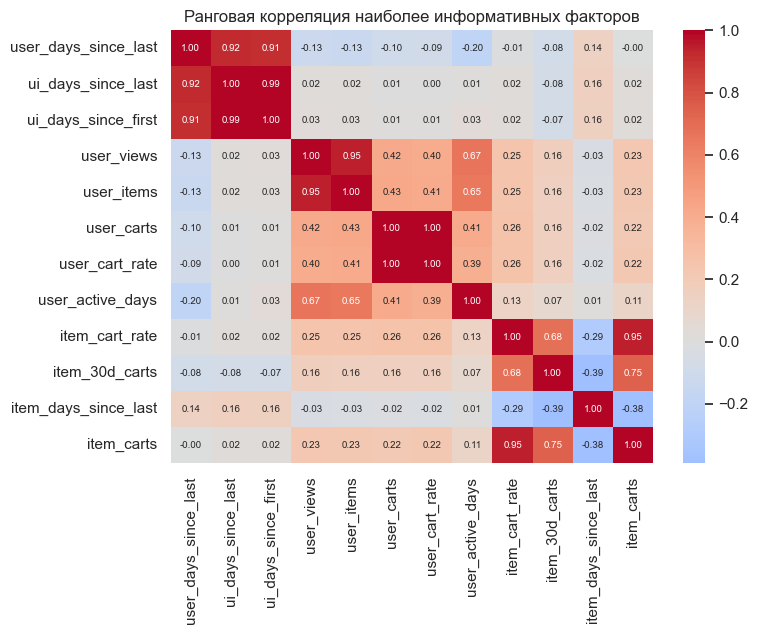

In [31]:
top_features = check.index[:12].tolist()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(dataset[top_features].corr(method='spearman'), cmap='coolwarm', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Ранговая корреляция наиболее информативных факторов')
plt.tight_layout(); plt.show()

Все факторы с содержательным смыслом отличаются от случайных (ROC AUC отдельного фактора заметно отклоняется от 0,5). Сильнее всего с будущей покупкой связаны давность последнего визита пользователя и последнего взаимодействия с товаром (чем меньше, тем выше вероятность покупки), общая активность пользователя, добавления в корзину, а также наличие товара и его недавняя популярность. Часть факторов сильно коррелирует между собой (например, счётчики активности пользователя).

**Ограничение.** В обучающей таблице очень мало положительных примеров: в кандидаты из истории попадает лишь около 6 % покупок целевого периода, остальные покупки совершают новые пользователи или покупаются товары, которые пользователь раньше не смотрел. На третьей неделе это нужно учесть: набрать больше положительных примеров за счёт нескольких временных срезов и расширить список кандидатов (популярные товары, товары из тех же категорий, коллаборативная фильтрация).

## Выводы

**Данные**

- Лог содержит 2,76 млн событий за 4,5 месяца: 1,41 млн пользователей, 235 тысяч товаров. Просмотры составляют 96,7 % событий, добавления в корзину 2,5 %, покупки 0,8 %.
- 71 % пользователей совершили единственное событие; есть 75 аномально активных посетителей (более 500 событий).
- Спрос очень разрежен: три самых продаваемых товара покрывают лишь 0,61 % будущих покупок.
- Свойства товаров: 20,3 млн записей, 1104 свойства, еженедельные снимки. Понятны по смыслу только категория и наличие; свойства есть примерно у 79 % товаров из лога.

**Валидация**

- Используется разбиение по времени: обучение до 18 августа 2015 года, тест последний месяц. Случайное разбиение привело бы к утечке будущего.
- Только 14 % покупателей теста известны по обучающему периоду, поэтому значения Precision@3 в задаче низкие. Базовые решения: 0,010 (популярные товары) и 0,019 (личная история).

**Факторы**

- Построены четыре группы факторов: временные признаки, факторы товара, пользователя и пары «пользователь–товар» (включая интерес пользователя к категории).
- Все факторы считаются функциями с параметром `cutoff` только по данным до заданного момента, включая свойства товаров. Это позволяет использовать один и тот же код для обучения, валидации и итогового сервиса.